In [1]:
import numpy as np
def report_stat(df):
    row_mean = df.mean(axis=1)
    row_std = df.std(axis=1)
    df_z = df.sub(row_mean, axis=0).div(row_std.mask(row_std < 1e-6, 1), axis=0)
    d = df.shape[0]  # number of features/dimensions
    norms = df_z.pow(2).sum(axis=0).pow(0.5)  # ||z|| per point, not squared
    norms_normalized = norms / (d ** 0.5)      # correct for dimension

    mean_norm = norms_normalized.mean()
    cv_norm = norms_normalized.std() / mean_norm
    return mean_norm, cv_norm
def report_inf_heatmap(df,size=(10,8)):

    diag = np.diag(df.values)  # array of diagonal elements, one per row/column
    df= df.sub(diag, axis=0)
    df.mask(np.isclose(df, 1e51), np.inf)
    import seaborn as sns
    import matplotlib.pyplot as plt

    plt.figure(figsize=size)
    sns.heatmap(df, annot=True, cmap='viridis')
    plt.show()


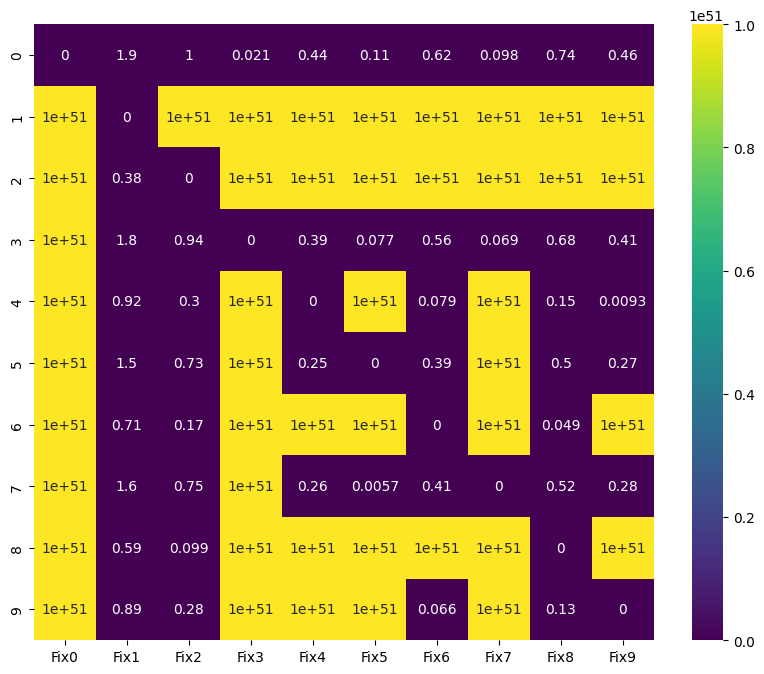

np.float64(0.6338028169014085)

In [9]:

from NSPLIB.src.instances.process.process_bloated import const_model
from pyomo.pyomo.common.numeric_types import value
from src.models.cz_model import CaoZavalaModel, CaoZavalaAlgo
sto_m = const_model()
m = CaoZavalaModel.from_sto_m(sto_m)
m.build()
from pyomo.opt import SolverFactory
from pyomo.environ import *


solver = SolverFactory(
    'baron',
    executable='/Users/jyang872/Desktop/baron/baron',options = {'EpsA': 1e-3, 'TDo':1,"AbsConFeasTol":1e-3,"NLPSol":9,
                                                                "LBTTDo":1,"OBTTDo":1,"MaxTime":3600,
                                                                'LicName': '/Users/jyang872/Desktop/baron/baronlice.txt'}
)

global_obj=-1134.1510553614544

y_ops={}
obj_ops={}
for s in range(0,10):
    solver.solve(m.aux_models["lbd"][s],tee=False,keepfiles=False)
    x_dict = {idx: value(m.aux_models["lbd"][s].y[idx]) for idx in m.aux_models["lbd"][s].y}
    y_ops[s]=x_dict
for fix_s in range(0,10):
    temp={}
    for s in range(0,10):
        m.fix_y_origin(y_ops[fix_s])
        results=solver.solve(m.aux_models["lbd"][s],tee=False,keepfiles=False)
        temp[s]=results['Problem'][0]['Upper bound']
    obj_ops["Fix"+str(fix_s)]=temp


import pandas as pd
df=pd.DataFrame(obj_ops)
report_inf_heatmap(df)
(df == 1e51).sum().sum()/(81-10)

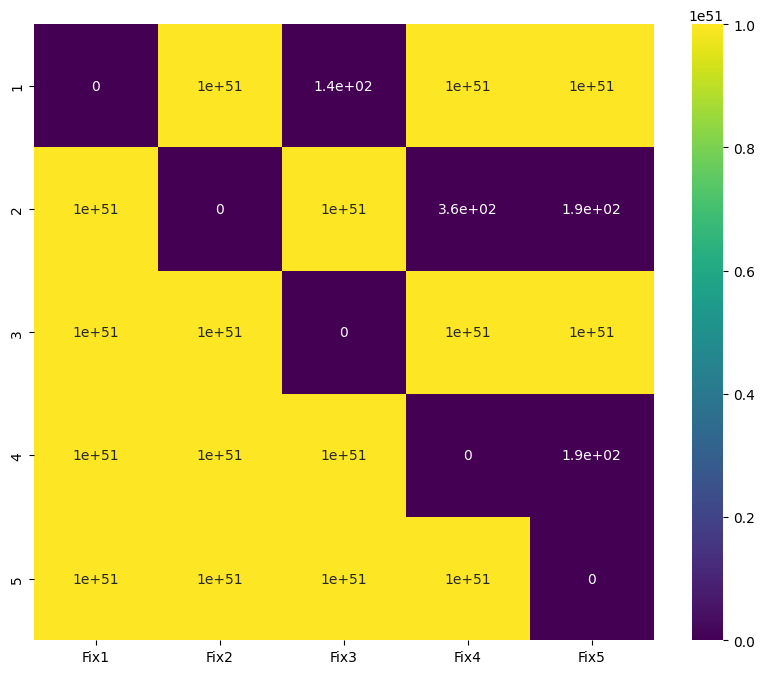

np.float64(0.8)

In [10]:
from NSPLIB.src.instances.crude_selection.crude_selection import const_model
from pyomo.pyomo.scripting.commands import pyomo
from src.models.cz_model import CaoZavalaModel, CaoZavalaAlgo
import cProfile
import numpy as np
from pyomo.environ import *
eps=0.5
sto_m = const_model()
m = CaoZavalaModel.from_sto_m(sto_m)
m.build()
binary_ys = [f'pickCrude[{i}]' for i in range(1, 10 + 1)]
binary_y_val = {y: 0 for y in binary_ys}
binary_y_val['pickCrude[2]'] = 1
binary_y_val['pickCrude[3]'] = 1
binary_y_val['pickCrude[4]'] = 1
binary_y_val['pickCrude[8]'] = 1
binary_y_val['pickCrude[10]'] = 1
m.fix_binary_y(binary_y_val)

solver = SolverFactory(
    'baron',
    executable='/Users/jyang872/Desktop/baron/baron',options = {'EpsA': 1e-3, 'TDo':1,"AbsConFeasTol":1e-3,"NLPSol":9,
                                                                "LBTTDo":1,"OBTTDo":1,"MaxTime":3600,
                                                                'LicName': '/Users/jyang872/Desktop/baron/baronlice.txt'}
)

global_obj=-18350.1

y_ops={}
obj_ops={}
for s in range(1,6):
    solver.solve(m.aux_models["lbd"][s],tee=False,keepfiles=False)
    x_dict = {idx: value(m.aux_models["lbd"][s].y[idx]) for idx in m.aux_models["lbd"][s].y}
    y_ops[s]=x_dict
for fix_s in range(1,6):
    m.fix_y_origin(y_ops[fix_s])
    temp={}
    for s in range(1,6):
        results=solver.solve(m.aux_models["lbd"][s],tee=False,keepfiles=False)
        temp[s]=results['Problem'][0]['Upper bound']
    obj_ops["Fix"+str(fix_s)]=temp


import pandas as pd
df=pd.DataFrame(obj_ops)
report_inf_heatmap(df)
(df == 1e51).sum().sum()/(25-5)